In [7]:
from getdist import MCSamples
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import sem, t
import arviz as az
from scipy.ndimage import gaussian_filter1d
from scipy.integrate import quad

###############################################################################à
# Define the equation of state w(z) for the w0-wa parametrization

# Define the equation of state w(z) for the w0-wa parametrization
def w(z, w0, wa):
    return w0 + wa * (z / (1 + z))

# Define the integrand for f_DE(z)
def integrand(z, w0, wa):
    return 3 * (1 + w(z, w0, wa)) / (1 + z)

# Define the function to compute f_DE(z) using numerical integration
def f_de(z, w0, wa):
    integral, _ = quad(integrand, 0, z, args=(w0, wa))
    return np.exp(integral)
#################################################################################


In [8]:
if 0 == 0:
    # Define the file paths for the chains
    files = [
        'w0wa_samples/chain.1.txt',
        'w0wa_samples/chain.2.txt',
        'w0wa_samples/chain.3.txt',
        'w0wa_samples/chain.4.txt',
    ]

    chains = []
    for file in files:
        data_printed = np.loadtxt(file, skiprows=1000)  # Skip the header
        chains.append(data_printed)
     
samples = np.concatenate(chains, axis=0)  # Concatenate along the rows

In [9]:
z_values = np.linspace(0, 2.35, 30)  # 100 punti tra 0 e 2.35

#num_samples = samples.shape[0] # Numero di campioni per ogni z
num_samples = len(samples)


# Supponendo che samples sia un array NumPy e che w possa essere vectorizzata
# Prealloca w_values
w_values = np.zeros((len(z_values), num_samples))

# Calcola i valori di w per ogni z e campione
for i, z in enumerate(z_values):
    # Estrai le colonne necessarie da samples
    sample_columns = samples[:num_samples, 2:4]  # Adatta l'intervallo in base alle tue necessità
    w_values[i, :] = w(z, *sample_columns.T)  # Usa unpacking per passare le colonne come argomenti
    
# Matrice dei valori di f_de per ogni z e campione
f_values = np.zeros((len(z_values), num_samples))

# Calcolo dei valori di f_de per ogni z e campione
for i, z in enumerate(z_values):
    for j in range(num_samples):
        f_values[i, j] = f_de(z, samples[j, 2], samples[j, 3])

In [10]:
import numpy as np
import getdist.plots as gpl
from getdist import plots, MCSamples
import getdist
import matplotlib.pyplot as plt
import IPython

names = ['H0rd', 'Omega_m', 'w0', 'wa']
labels =  ['H0rd', 'Omega_m','w0', 'wa' ]
sample = MCSamples(samples=samples,names = names, labels = labels)

mean= [0,0,0,0]
print("GETDIST INTERVAL")
for i, name in enumerate(names):
    mean[i]=sample.mean(names[i])
    std=sample.std(names[i])
    print("",sample.getInlineLatex(names[i],limit=1),f"std is : {std}")# lim 1 68 ,lim 2 95

# Calcola la media
w0 = mean[2]
wa = mean[3]

Removed no burn in
GETDIST INTERVAL
 H0rd = 9632^{+340}_{-530} std is : 453.8762381770572
 Omega_m = 0.344^{+0.047}_{-0.026} std is : 0.04099412062743795
 w0 = -0.54^{+0.39}_{-0.21} std is : 0.30965805315267986
 wa = -1.67^{+0.36}_{-1.3} std is : 1.0692553311837831


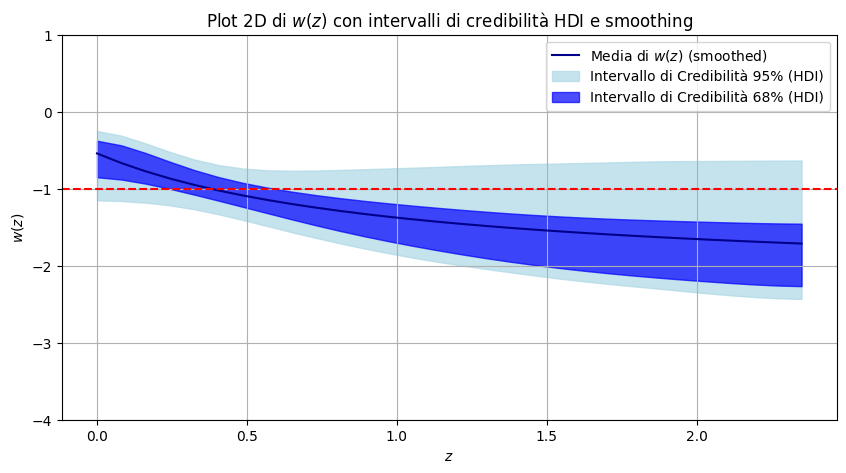

In [12]:
#calcola la media
w_mean = np.zeros((len(z_values)))
for i,z in enumerate(z_values):
    w_mean[i] = w(z, c1, c2, c3, c4)


# Calcola gli HDI usando ArviZ
hdi_68 = np.zeros((len(z_values), 2))  # per memorizzare gli HDI del 68%
hdi_95 = np.zeros((len(z_values), 2))  # per memorizzare gli HDI del 95%

for i in range(len(z_values)):
    hdi_68[i] = az.hdi(w_values[i], hdi_prob=0.68)  # 68% HDI
    hdi_95[i] = az.hdi(w_values[i], hdi_prob=0.95)  # 95% HDI

# Estrai i limiti degli intervalli HDI
lower_bound_68 = hdi_68[:, 0]
upper_bound_68 = hdi_68[:, 1]
lower_bound_95 = hdi_95[:, 0]
upper_bound_95 = hdi_95[:, 1]

# Smoothing con filtro gaussiano
sigma = 2  # Scegli un valore adatto per lo smoothing
lower_bound_68_smooth = gaussian_filter1d(lower_bound_68, sigma=sigma)
upper_bound_68_smooth = gaussian_filter1d(upper_bound_68, sigma=sigma)
lower_bound_95_smooth = gaussian_filter1d(lower_bound_95, sigma=sigma)
upper_bound_95_smooth = gaussian_filter1d(upper_bound_95, sigma=sigma)

# Crea un grafico 2D con bande di confidenza smooth
plt.figure(figsize=(10, 5))
plt.plot(z_values, w_mean, label='Media di $w(z)$ (smoothed)', color='darkblue')

# Bande di confidenza 95% smooth
plt.fill_between(z_values, lower_bound_95_smooth, upper_bound_95_smooth, color='lightblue', alpha=0.7, label='Intervallo di Credibilità 95% (HDI)')

# Bande di confidenza 68% smooth
plt.fill_between(z_values, lower_bound_68_smooth, upper_bound_68_smooth, color='blue', alpha=0.7, label='Intervallo di Credibilità 68% (HDI)')

# Aggiungi titoli e etichette
plt.title('Plot 2D di $w(z)$ con intervalli di credibilità HDI e smoothing')
plt.xlabel('$z$')
plt.ylabel('$w(z)$')
plt.legend()
plt.axhline(y=-1, color='red', linestyle='--', label='$y = 1$', linewidth=1.5)
plt.grid()
plt.ylim(-4, 1)
plt.show()

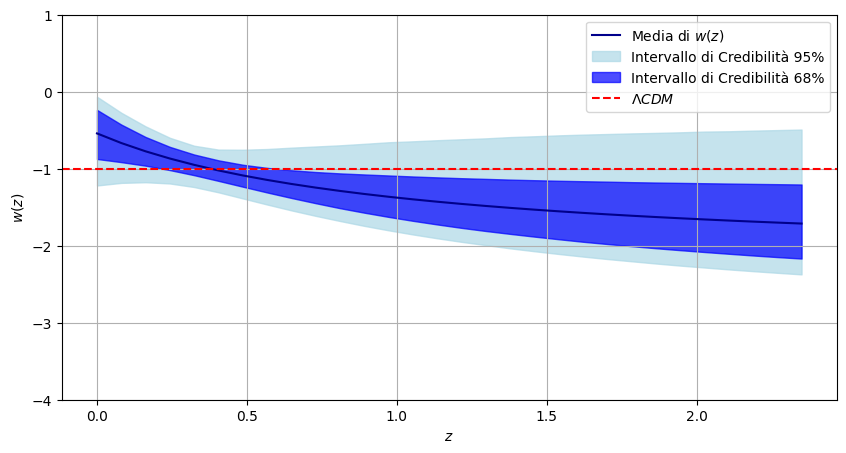

In [16]:

# Supponiamo che w_values sia già definito come un array di campioni
# Calcola gli intervalli di confidenza per il 68% e il 95%
lower_bound_68, upper_bound_68 = compute_confidence_intervals(w_values, 0.68)
lower_bound_95, upper_bound_95 = compute_confidence_intervals(w_values, 0.95)


# Crea un grafico 2D con bande di confidenza
plt.figure(figsize=(10, 5))
plt.plot(z_values, w_mean, label='Media di $w(z)$', color='darkblue')

# Bande di confidenza 95%
plt.fill_between(z_values, lower_bound_95, upper_bound_95, color='lightblue', alpha=0.7, label='Intervallo di Credibilità 95%')

# Bande di confidenza 68%
plt.fill_between(z_values, lower_bound_68, upper_bound_68, color='blue', alpha=0.7, label='Intervallo di Credibilità 68%')

# Aggiungi titoli e etichette
plt.title('Plot  di $w(z)$ per la parametrizazione $w_0w_a BAO$')
plt.xlabel('$z$')
plt.ylabel('$w(z)$')
plt.axhline(y=-1, color='red', linestyle='--', label='$\Lambda CDM$', linewidth=1.5)
plt.legend()
plt.grid()
plt.ylim(-4, 1)
plt.show()

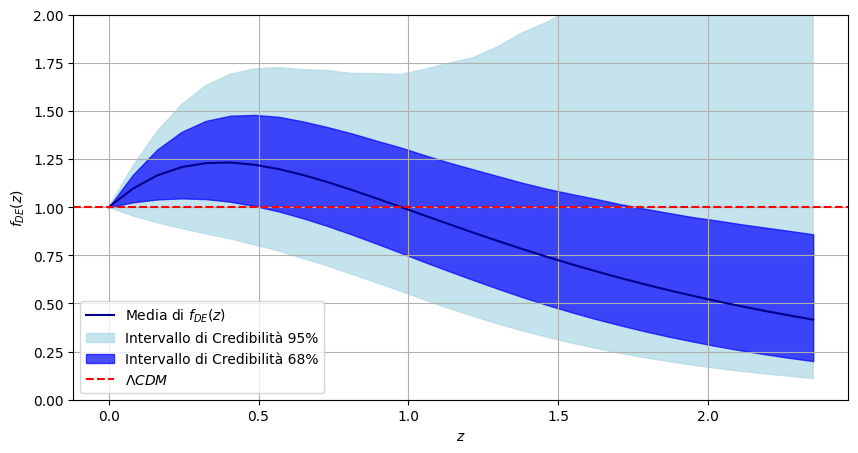

In [15]:
import numpy as np
import matplotlib.pyplot as plt

#calcola la media
f = np.zeros((len(z_values)))
for i,z in enumerate(z_values):
    f[i] = f_de(z, w0, wa)

# Calcola gli intervalli di confidenza usando i percentili
def compute_confidence_intervals(data, confidence_level):
    lower_percentile = (1 - confidence_level) / 2 * 100
    upper_percentile = (1 + confidence_level) / 2 * 100
    lower_bound = np.percentile(data, lower_percentile, axis=1)
    upper_bound = np.percentile(data, upper_percentile, axis=1)
    return lower_bound, upper_bound

# Supponiamo che f_values sia già definito come un array di campioni
lower_bound_68, upper_bound_68 = compute_confidence_intervals(f_values, 0.68)
lower_bound_95, upper_bound_95 = compute_confidence_intervals(f_values, 0.95)
# Crea un grafico 2D con bande di confidenza
plt.figure(figsize=(10, 5))
plt.plot(z_values, f, label='Media di $f_{DE}(z)$ ', color='darkblue')

# Bande di confidenza 95%
plt.fill_between(z_values, lower_bound_95, upper_bound_95, color='lightblue', alpha=0.7, label='Intervallo di Credibilità 95%')

# Bande di confidenza 68%
plt.fill_between(z_values, lower_bound_68, upper_bound_68, color='blue', alpha=0.7, label='Intervallo di Credibilità 68%')

# Aggiungi titoli e etichette
#plt.title('Plot di $f_{DE}(z)$ per la parametrizzazione $w_0w_a BAO$')
plt.xlabel('$z$')
plt.ylabel('$f_{DE}(z)$')
plt.axhline(y=1, color='red', linestyle='--', label='$\Lambda CDM$', linewidth=1.5)
plt.legend()
plt.grid()
plt.ylim(0, 2)
plt.show()
